#Level３（★★★☆）

In Level 3, you will train a model and make predictions using the data with outliers removed, based on the scatter plot

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 3.1. Preprocessing Data

In [2]:
import pandas as pd

df = pd.read_csv('Car_Price_Data.csv')
df = df.dropna()

In Level 2, we focused on detecting outliers by examining individual variables using a boxplot, identifying six outliers.

Now in Level 3, we shift our focus to identifying outliers visually using scatter plots.

Let’s begin by revisiting the scatter plot of `engine-size` versus `price` that we explored in Level 1.
In the scatter plot (left graph), the orange points correspond to the data identified as outliers as we saw in Level 2.


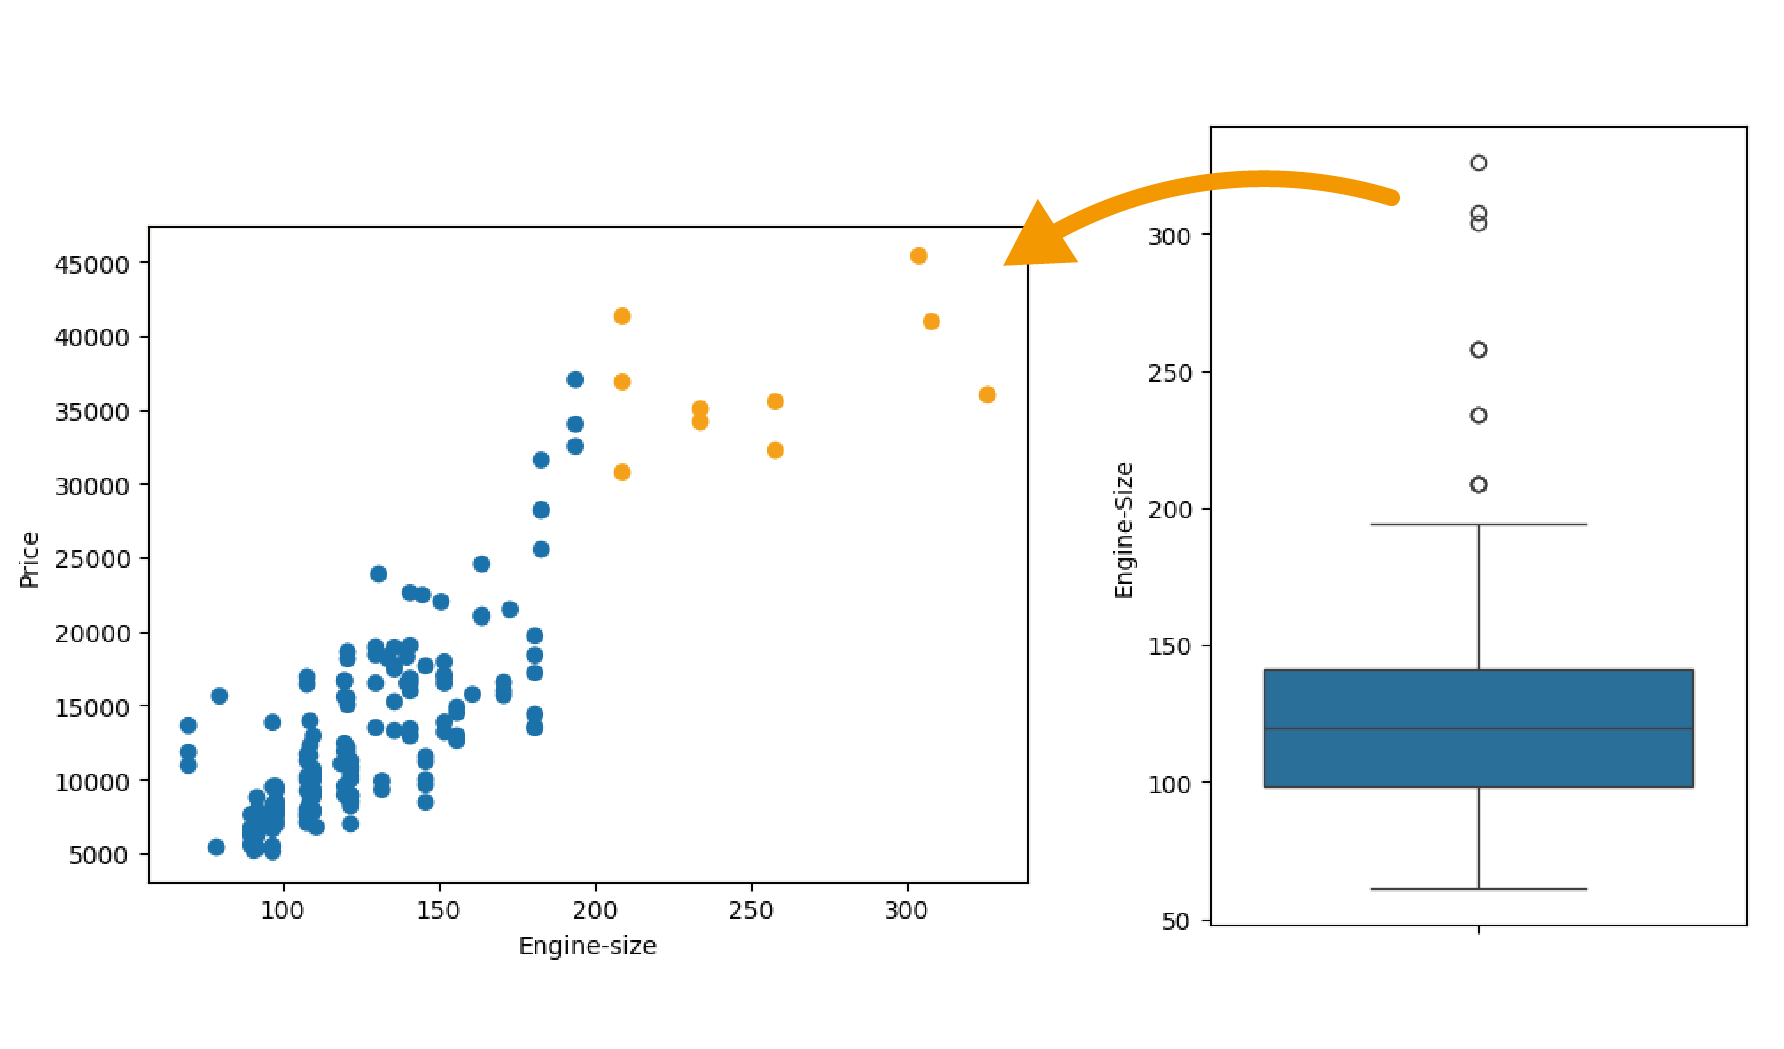

This time, we want to keep only the data where the `city-mpg` value is 40 or less. As we did in Level 2, you can use a comparison operator to set this condition, as shown below.


In [3]:
is_under_40 = df['city-mpg'] <= 40
df = df[is_under_40]

Let’s check whether the target data points have actually been removed. We’ll create a scatter plot to confirm.

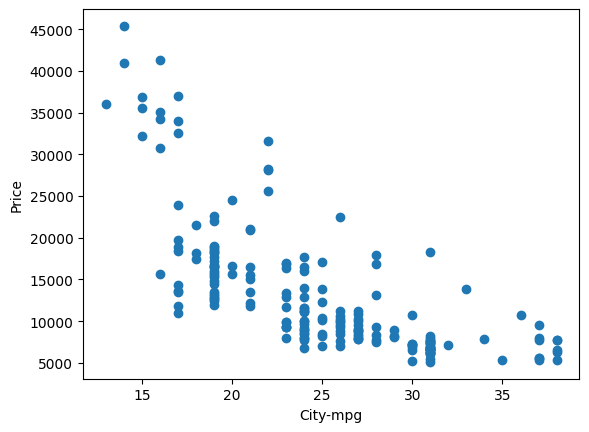

In [4]:
import matplotlib.pyplot as plt

plt.scatter(df['city-mpg'], df['price'])
plt.xlabel('City-mpg')
plt.ylabel('Price')
plt.show()

This time, compared to the `city-mpg` case, the outliers are in slightly more complex positions. Let’s consider a condition that applies only to these three specific data points.

We can determine that the condition applying only to the outliers is:

`curb-weight` is 3000 or less, and `price` is 30,000 or more.


First, let us extract only the data points that meet the condition for outliers.

In [5]:
df_out = df[(df['curb-weight'] <= 3000) & (df['price'] >= 30000)]

Let’s check whether exactly three data points matching the condition have been correctly extracted.

In [6]:
df_out

,engine-size,city-mpg,curb-weight,price
126,194,17,2756,32528.0
127,194,17,2756,34028.0
128,194,17,2800,37028.0


At this point, only the data excluding the outliers should remain. Let’s check whether the intended data points have been successfully removed.

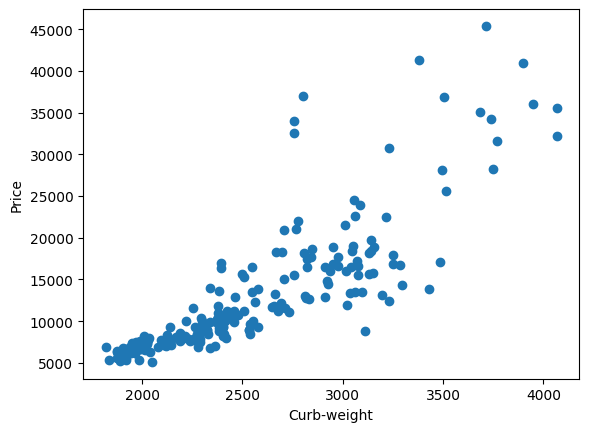

In [7]:
plt.scatter(df['curb-weight'], df['price'])
plt.xlabel('Curb-weight')
plt.ylabel('Price')
plt.show()

As always, we will divide the data into **Explanatory variable** and **Target variable**.


In [8]:
X = df.drop('price', axis=1)
y = df['price']

##3.2. Model Building and Evaluation

The training process is the same as before.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=0)

scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

print('R² score for each split:', scores)
print('Average R² score from cross-validation:', scores.mean())

R² score for each split: [0.81941649 0.67030353 0.82828601 0.77415231 0.7425054 ]
Average R² score from cross-validation: 0.766932749828775


After removing outliers using the scatter plot, the average R² increased compared to Level 1 (no outlier processing) and Level 2 (outliers removed using box plots).
This shows that the impact of outlier processing on model accuracy can vary from case to case.
And this doesn’t apply only to outlier removal—trying different approaches is essential for improving model accuracy.

##3.3. Practice Problems

**Q3-1.** Download the `Regression_Lv3_Practice.csv` from the link below, upload the file, and load it as a pandas DataFrame.
Then display the first 5 rows to check the data.

[Regression_Lv3_Practice.csv](https://drive.google.com/file/d/1vIha3Pn9FAa4OWuGLjpP-VL1Bns9dK_e/view?usp=drive_link)


In [12]:
import pandas as pd
df = pd.read_csv('Regression_Lv3_Practice.csv')
df.head()

,engine-size,price
0,196,23940
1,81,11691
2,170,22229
3,279,14177
4,62,2756


**Q3-2.** Using the DataFrame loaded from Q3-1, create a scatter plot with `engine-size` on the x-axis and `price` on the y-axis.

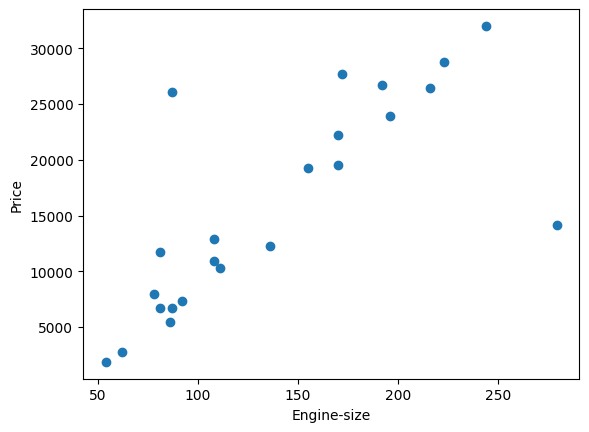

In [13]:
import matplotlib.pyplot as plt

# Create scatter plot
plt.scatter(df['engine-size'], df['price'])
plt.xlabel('Engine-size')
plt.ylabel('Price')
plt.show()

**Q3-3.**
Remove the outliers in the area circled in red in the figure.

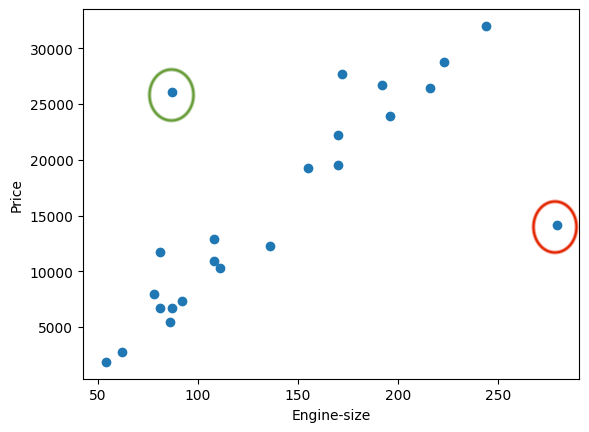

In [15]:
# Remove the red circled outlier (high engine-size, low price)
df_no_red = df[df['engine-size'] <= 250]
df_no_red

,engine-size,price
0,196,23940
1,81,11691
2,170,22229
4,62,2756
5,223,28764
6,170,19557
7,192,26754
8,54,1869
9,244,32015
10,216,26453


**Q3-4.** Remove the outliers in the area circled in green in the figure from Q3-3.

In [16]:
# Remove the green circled outlier from the updated DataFrame
df_clean = df_no_red[~((df_no_red['engine-size'] < 100) & (df_no_red['price'] > 20000))]
df_clean

,engine-size,price
0,196,23940
1,81,11691
2,170,22229
4,62,2756
5,223,28764
6,170,19557
7,192,26754
8,54,1869
9,244,32015
10,216,26453
